# Assignment 7 — Apriori Algorithm for Association Rule Mining

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris



## Part A: Dataset and Transaction Preparation

### Task 1: Load and Inspect the Iris Dataset


In [2]:
iris = load_iris()

X = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

print("Number of transactions:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:", feature_names)
print("Class names:", class_names)


Number of transactions: 150
Number of features: 4
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']


### Task 2: Separate Measurements and Species/Class Label

In [3]:
feature_data = X.copy()
species_labels = class_names[y]

feature_df = pd.DataFrame(feature_data, columns=feature_names)
feature_df["species"] = species_labels

feature_df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Answer:** The four numerical measurements are kept in `feature_data`, while the Iris species label is stored separately in `species_labels`. The combined `feature_df` is used for convenient inspection before transaction conversion.


### Task 3: Calculate the 1/3 and 2/3 Quantiles


In [4]:
quantiles = {}

for feature in feature_names:
    q1_3 = np.quantile(feature_df[feature].values, 1/3)
    q2_3 = np.quantile(feature_df[feature].values, 2/3)
    quantiles[feature] = (q1_3, q2_3)

quantile_table = pd.DataFrame(
    [(feature, values[0], values[1]) for feature, values in quantiles.items()],
    columns=["Feature", "1/3 Quantile", "2/3 Quantile"]
)

quantile_table


,Feature,1/3 Quantile,2/3 Quantile
0,sepal length (cm),5.400000,6.3
1,sepal width (cm),2.900000,3.2
2,petal length (cm),2.633333,4.9
3,petal width (cm),0.866667,1.6


### Task 4: Convert Numerical Features into Low, Medium, and High Categories

In [5]:
def categorize_value(value, lower_boundary, upper_boundary):
    if value < lower_boundary:
        return "low"
    elif value < upper_boundary:
        return "medium"
    else:
        return "high"

categorical_df = pd.DataFrame(index=feature_df.index)

for feature in feature_names:
    lower, upper = quantiles[feature]
    categorical_df[feature] = feature_df[feature].apply(
        lambda value: categorize_value(value, lower, upper)
    )

categorical_df["species"] = species_labels
categorical_df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,low,high,low,low,setosa
1,low,medium,low,low,setosa
2,low,high,low,low,setosa
3,low,medium,low,low,setosa
4,low,high,low,low,setosa


### Task 5: Represent Each Record as a Transaction

In [6]:
transactions = []

for _, row in categorical_df.iterrows():
    transaction = {
        f"sepal_length={row[feature_names[0]]}",
        f"sepal_width={row[feature_names[1]]}",
        f"petal_length={row[feature_names[2]]}",
        f"petal_width={row[feature_names[3]]}",
        f"species={row['species']}"
    }
    transactions.append(transaction)

print("First 10 transactions:")
for i, transaction in enumerate(transactions[:10], start=1):
    print(f"T{i}: {transaction}")

print("\nEvery transaction is a set:", all(isinstance(t, set) for t in transactions))


First 10 transactions:
T1: {'petal_length=low', 'sepal_width=high', 'petal_width=low', 'sepal_length=low', 'species=setosa'}
T2: {'petal_length=low', 'petal_width=low', 'sepal_length=low', 'species=setosa', 'sepal_width=medium'}
T3: {'petal_length=low', 'sepal_width=high', 'petal_width=low', 'sepal_length=low', 'species=setosa'}
T4: {'petal_length=low', 'petal_width=low', 'sepal_length=low', 'species=setosa', 'sepal_width=medium'}
T5: {'petal_length=low', 'sepal_width=high', 'petal_width=low', 'sepal_length=low', 'species=setosa'}
T6: {'petal_length=low', 'sepal_width=high', 'sepal_length=medium', 'petal_width=low', 'species=setosa'}
T7: {'petal_length=low', 'sepal_width=high', 'petal_width=low', 'sepal_length=low', 'species=setosa'}
T8: {'petal_length=low', 'sepal_width=high', 'petal_width=low', 'sepal_length=low', 'species=setosa'}
T9: {'petal_length=low', 'petal_width=low', 'sepal_length=low', 'species=setosa', 'sepal_width=medium'}
T10: {'petal_length=low', 'petal_width=low', 'sepa

## Task 1: Inspect the Transaction Database

In [7]:
unique_items = sorted(set().union(*transactions))

print("Total number of transactions:", len(transactions))
print("Complete set of unique items:")
for item in unique_items:
    print(item)

print("Number of unique items:", len(unique_items))

selected_items = unique_items[:5]
print("\nOccurrence counts for five selected items:")

for item in selected_items:
    count = sum(item in transaction for transaction in transactions)
    print(f"{item}: {count}")


Total number of transactions: 150
Complete set of unique items:
petal_length=high
petal_length=low
petal_length=medium
petal_width=high
petal_width=low
petal_width=medium
sepal_length=high
sepal_length=low
sepal_length=medium
sepal_width=high
sepal_width=low
sepal_width=medium
species=setosa
species=versicolor
species=virginica
Number of unique items: 15

Occurrence counts for five selected items:
petal_length=high: 51
petal_length=low: 50
petal_length=medium: 49
petal_width=high: 52
petal_width=low: 50


**Why this is a transaction database:** Each Iris record can be represented as a set of categorical Boolean items. An item either occurs in a transaction or does not occur, which matches the representation used by Boolean association-rule mining.


## Task 2: Implement Support

For an itemset \(I\),

\[
support(I) = \frac{count(I)}{N}
\]

where `count(I)` is the number of transactions containing every item in \(I\), and \(N\) is the total number of transactions.


In [8]:
def support(itemset, transactions):
    itemset = set(itemset)
    count = sum(itemset.issubset(transaction) for transaction in transactions)
    return count / len(transactions)


def support_count(itemset, transactions):
    itemset = set(itemset)
    return sum(itemset.issubset(transaction) for transaction in transactions)


test_itemsets = [
    {unique_items[0]},
    {unique_items[1]},
    {unique_items[2]},
    {unique_items[0], unique_items[1]},
    {unique_items[0], unique_items[2]},
    {unique_items[1], unique_items[2]}
]

support_test_rows = []

for itemset in test_itemsets:
    count = support_count(itemset, transactions)
    sup = support(itemset, transactions)
    support_test_rows.append({
        "Itemset": ", ".join(sorted(itemset)),
        "Count": count,
        "Support": sup,
        "Support (%)": 100 * sup
    })

support_test_table = pd.DataFrame(support_test_rows)
support_test_table


,Itemset,Count,Support,Support (%)
0,petal_length=high,51,0.340000,34.000000
1,petal_length=low,50,0.333333,33.333333
2,petal_length=medium,49,0.326667,32.666667
3,"petal_length=high, petal_length=low",0,0.000000,0.000000
4,"petal_length=high, petal_length=medium",0,0.000000,0.000000
5,"petal_length=low, petal_length=medium",0,0.000000,0.000000


## Task 3: Support and Confidence for an Association Rule



In [9]:
def confidence(antecedent, consequent, transactions):
    antecedent = set(antecedent)
    consequent = set(consequent)

    antecedent_count = support_count(antecedent, transactions)
    union_count = support_count(antecedent | consequent, transactions)

    if antecedent_count == 0:
        return 0.0

    return union_count / antecedent_count


antecedent = {"petal_length=low"}
consequent = {"species=setosa"}

rule_support = support(antecedent | consequent, transactions)
rule_confidence = confidence(antecedent, consequent, transactions)

print("Rule:", antecedent, "->", consequent)
print("Support:", rule_support)
print("Confidence:", rule_confidence)


Rule: {'petal_length=low'} -> {'species=setosa'}
Support: 0.3333333333333333
Confidence: 1.0


**Why confidence is directional:** Confidence conditions on the antecedent. Therefore \(A\rightarrow B\) divides by `count(A)`, while \(B\rightarrow A\) divides by `count(B)`. The combined count `count(A ∪ B)` is the same, but the denominators can differ, so the two confidence values can differ.


In [10]:
reverse_confidence = confidence(consequent, antecedent, transactions)
reverse_support = support(consequent | antecedent, transactions)

comparison_rules = pd.DataFrame([
    {
        "Rule": "A -> B",
        "Support": rule_support,
        "Confidence": rule_confidence
    },
    {
        "Rule": "B -> A",
        "Support": reverse_support,
        "Confidence": reverse_confidence
    }
])

comparison_rules


,Rule,Support,Confidence
0,A -> B,0.333333,1.0
1,B -> A,0.333333,1.0


## Task 4: Set Minimum Thresholds

The main experiment uses:

- **Minimum support = 0.20 (20%)**
- **Minimum confidence = 0.70 (70%)**

**Answer:** Minimum support controls which itemsets are considered frequent enough to continue through the Apriori search. Minimum confidence controls which frequent-itemset-derived rules are accepted as sufficiently reliable in terms of conditional co-occurrence. Both thresholds are needed because a frequent itemset does not automatically imply that every rule formed from it has high confidence.


# Part B: Apriori Candidate Generation

## Task 5: Generate C1 and L1

In [11]:
MIN_SUPPORT = 0.20
MIN_CONFIDENCE = 0.70

C1 = [{item} for item in unique_items]

C1_rows = []
for candidate in C1:
    count = support_count(candidate, transactions)
    sup = count / len(transactions)
    C1_rows.append({
        "Itemset": ", ".join(sorted(candidate)),
        "Count": count,
        "Support": sup,
        "Frequent?": sup >= MIN_SUPPORT
    })

C1_table = pd.DataFrame(C1_rows).sort_values(
    by=["Support", "Itemset"], ascending=[False, True]
).reset_index(drop=True)

L1 = [candidate for candidate in C1
      if support(candidate, transactions) >= MIN_SUPPORT]

print("C1:")
display(C1_table)

print("\nL1:")
display(pd.DataFrame([
    {
        "Itemset": ", ".join(sorted(itemset)),
        "Count": support_count(itemset, transactions),
        "Support": support(itemset, transactions)
    }
    for itemset in L1
]))


C1:


,Itemset,Count,Support,Frequent?
0,sepal_width=high,56,0.373333,True
1,sepal_length=medium,53,0.353333,True
2,petal_width=high,52,0.346667,True
3,petal_length=high,51,0.340000,True
4,sepal_length=high,51,0.340000,True
5,petal_length=low,50,0.333333,True
6,petal_width=low,50,0.333333,True
7,species=setosa,50,0.333333,True
8,species=versicolor,50,0.333333,True
9,species=virginica,50,0.333333,True



L1:


,Itemset,Count,Support
0,petal_length=high,51,0.340000
1,petal_length=low,50,0.333333
2,petal_length=medium,49,0.326667
3,petal_width=high,52,0.346667
4,petal_width=low,50,0.333333
5,petal_width=medium,48,0.320000
6,sepal_length=high,51,0.340000
7,sepal_length=low,46,0.306667
8,sepal_length=medium,53,0.353333
9,sepal_width=high,56,0.373333


## Task 6: Implement the Join Step


In [12]:
from itertools import combinations


def generate_candidates(previous_L):
    previous_L = [frozenset(itemset) for itemset in previous_L]

    if not previous_L:
        return []

    k_minus_1 = len(next(iter(previous_L)))
    k = k_minus_1 + 1

    candidates = set()

    for i in range(len(previous_L)):
        for j in range(i + 1, len(previous_L)):
            union = previous_L[i] | previous_L[j]

            if len(union) == k:
                candidates.add(frozenset(union))

    return sorted(candidates, key=lambda itemset: tuple(sorted(itemset)))


C2 = generate_candidates(L1)

print("Number of C2 candidates:", len(C2))
print("C2:")
for candidate in C2:
    print(set(candidate))


Number of C2 candidates: 105
C2:
{'petal_length=low', 'petal_length=high'}
{'petal_length=high', 'petal_length=medium'}
{'petal_length=high', 'petal_width=high'}
{'petal_width=low', 'petal_length=high'}
{'petal_length=high', 'petal_width=medium'}
{'petal_length=high', 'sepal_length=high'}
{'petal_length=high', 'sepal_length=low'}
{'petal_length=high', 'sepal_length=medium'}
{'petal_length=high', 'sepal_width=high'}
{'petal_length=high', 'sepal_width=low'}
{'sepal_width=medium', 'petal_length=high'}
{'petal_length=high', 'species=setosa'}
{'petal_length=high', 'species=versicolor'}
{'species=virginica', 'petal_length=high'}
{'petal_length=low', 'petal_length=medium'}
{'petal_length=low', 'petal_width=high'}
{'petal_width=low', 'petal_length=low'}
{'petal_length=low', 'petal_width=medium'}
{'petal_length=low', 'sepal_length=high'}
{'petal_length=low', 'sepal_length=low'}
{'petal_length=low', 'sepal_length=medium'}
{'petal_length=low', 'sepal_width=high'}
{'petal_length=low', 'sepal_width

## Task 7: Implement the Prune Step


In [19]:
def prune_candidates(candidates, previous_L):
    previous_L = {frozenset(itemset) for itemset in previous_L}
    kept = []
    removed = []

    for candidate in candidates:
        candidate = frozenset(candidate)
        k = len(candidate)
        required_subsets = [
            frozenset(subset)
            for subset in combinations(candidate, k - 1)
        ]

        missing_subsets = [
            subset for subset in required_subsets
            if subset not in previous_L
        ]

        if not missing_subsets:
            kept.append(candidate)
        else:
            removed.append((candidate, missing_subsets))

    return kept, removed


C2_pruned, C2_removed = prune_candidates(C2, L1)

print("C2 before pruning:", len(C2))
print("C2 after pruning:", len(C2_pruned))

if len(C2_removed) == 0:
    print("Nothing to remove.")
else:
    print("\nExamples of removed candidates:")
    for candidate, missing in C2_removed:
        print("Candidate:", set(candidate))
    else:
        print("Missing frequent subset(s):", [set(s) for s in missing])


C2 before pruning: 105
C2 after pruning: 105
Nothing to remove.


## Task 8: Count Candidate Supports

In [20]:
def count_candidate_supports(candidates, transactions):
    rows = []

    for candidate in candidates:
        count = support_count(candidate, transactions)
        sup = count / len(transactions)

        rows.append({
            "Itemset": ", ".join(sorted(candidate)),
            "Count": count,
            "Support": sup
        })

    return pd.DataFrame(rows).sort_values(
        by=["Support", "Itemset"], ascending=[False, True]
    ).reset_index(drop=True)


C2_counts = count_candidate_supports(C2_pruned, transactions)
C2_counts


,Itemset,Count,Support
0,"petal_length=low, petal_width=low",50,0.333333
1,"petal_length=low, species=setosa",50,0.333333
2,"petal_width=low, species=setosa",50,0.333333
3,"petal_length=high, species=virginica",47,0.313333
4,"petal_width=high, species=virginica",47,0.313333
...,...,...,...
100,"sepal_width=high, sepal_width=medium",0,0.000000
101,"sepal_width=low, sepal_width=medium",0,0.000000
102,"species=setosa, species=versicolor",0,0.000000
103,"species=setosa, species=virginica",0,0.000000


## Task 9: Complete the Apriori Algorithm


In [21]:
def apriori(transactions, min_support=0.20):
    transactions = [set(t) for t in transactions]
    unique_items = sorted(set().union(*transactions))

    frequent_itemsets = {}
    candidate_statistics = []

    # C1
    candidates = [frozenset([item]) for item in unique_items]

    level = 1

    while candidates:
        before_pruning = len(candidates)

        # C1 does not need a subset-pruning step.
        if level == 1:
            pruned_candidates = candidates
        else:
            previous_L = frequent_itemsets[level - 1]
            pruned_candidates, _ = prune_candidates(candidates, previous_L)

        after_pruning = len(pruned_candidates)

        candidate_rows = []
        frequent_level = []

        for candidate in pruned_candidates:
            count = support_count(candidate, transactions)
            sup = count / len(transactions)

            candidate_rows.append({
                "Itemset": candidate,
                "Count": count,
                "Support": sup
            })

            if sup >= min_support:
                frequent_level.append(candidate)

        frequent_itemsets[level] = frequent_level

        candidate_statistics.append({
            "k": level,
            "Candidates before pruning": before_pruning,
            "Candidates after pruning": after_pruning,
            "Frequent itemsets": len(frequent_level)
        })

        if not frequent_level:
            break

        candidates = generate_candidates(frequent_level)
        level += 1

    return frequent_itemsets, pd.DataFrame(candidate_statistics)


frequent_itemsets, candidate_statistics = apriori(
    transactions,
    min_support=MIN_SUPPORT
)

candidate_statistics


,k,Candidates before pruning,Candidates after pruning,Frequent itemsets
0,1,15,15,15
1,2,105,105,21
2,3,18,15,13
3,4,7,3,3
4,5,1,0,0


## Task 10: Display All Frequent Itemsets

In [22]:
def frequent_itemsets_table(frequent_itemsets):
    rows = []

    for k in sorted(frequent_itemsets):
        for itemset in frequent_itemsets[k]:
            rows.append({
                "k": k,
                "Itemset": ", ".join(sorted(itemset)),
                "Count": support_count(itemset, transactions),
                "Support": support(itemset, transactions),
                "Support (%)": 100 * support(itemset, transactions)
            })

    return pd.DataFrame(rows).sort_values(
        by=["k", "Support", "Itemset"],
        ascending=[True, False, True]
    ).reset_index(drop=True)


all_frequent_table = frequent_itemsets_table(frequent_itemsets)
display(all_frequent_table)

total_frequent = len(all_frequent_table)
largest_k = max(frequent_itemsets.keys())

print("Total number of frequent itemsets:", total_frequent)
print("Largest frequent itemset size:", largest_k)


,k,Itemset,Count,Support,Support (%)
0,1,sepal_width=high,56,0.373333,37.333333
1,1,sepal_length=medium,53,0.353333,35.333333
2,1,petal_width=high,52,0.346667,34.666667
3,1,petal_length=high,51,0.340000,34.000000
4,1,sepal_length=high,51,0.340000,34.000000
5,1,petal_length=low,50,0.333333,33.333333
6,1,petal_width=low,50,0.333333,33.333333
7,1,species=setosa,50,0.333333,33.333333
8,1,species=versicolor,50,0.333333,33.333333
9,1,species=virginica,50,0.333333,33.333333


Total number of frequent itemsets: 52
Largest frequent itemset size: 5


## Task 11: Verify the Apriori Property

In [23]:
def all_nonempty_subsets(itemset):
    itemset = list(itemset)
    subsets = []

    for r in range(1, len(itemset)):
        subsets.extend(
            frozenset(s)
            for s in combinations(itemset, r)
        )

    return subsets


large_frequent_itemsets = [
    itemset
    for k, level in frequent_itemsets.items()
    if k >= 3
    for itemset in level
][:3]

for itemset in large_frequent_itemsets:
    print("\nFrequent itemset:", set(itemset))

    for subset in all_nonempty_subsets(itemset):
        subset_k = len(subset)
        is_frequent = subset in set(frequent_itemsets.get(subset_k, []))

        print(
            f"Subset {set(subset)} "
            f"(level {subset_k}) -> frequent: {is_frequent}"
        )



Frequent itemset: {'petal_length=high', 'petal_width=high', 'sepal_length=high'}
Subset {'petal_length=high'} (level 1) -> frequent: True
Subset {'petal_width=high'} (level 1) -> frequent: True
Subset {'sepal_length=high'} (level 1) -> frequent: True
Subset {'petal_length=high', 'petal_width=high'} (level 2) -> frequent: True
Subset {'petal_length=high', 'sepal_length=high'} (level 2) -> frequent: True
Subset {'petal_width=high', 'sepal_length=high'} (level 2) -> frequent: True

Frequent itemset: {'species=virginica', 'petal_length=high', 'petal_width=high'}
Subset {'species=virginica'} (level 1) -> frequent: True
Subset {'petal_length=high'} (level 1) -> frequent: True
Subset {'petal_width=high'} (level 1) -> frequent: True
Subset {'species=virginica', 'petal_length=high'} (level 2) -> frequent: True
Subset {'species=virginica', 'petal_width=high'} (level 2) -> frequent: True
Subset {'petal_length=high', 'petal_width=high'} (level 2) -> frequent: True

Frequent itemset: {'species=vir

**Observation:** The Apriori property reduces the search space because any candidate with an infrequent subset cannot possibly be frequent itself. Such candidates can be discarded before performing a full support count for the larger itemset.


## Task 12: Generate Association Rules from Frequent Itemsets

In [24]:
def generate_rules(frequent_itemsets, transactions, min_confidence=0.70):
    rules = []

    for k, level in frequent_itemsets.items():
        if k < 2:
            continue

        for itemset in level:
            itemset = frozenset(itemset)

            # Every non-empty proper subset is an antecedent.
            for r in range(1, len(itemset)):
                for antecedent_tuple in combinations(itemset, r):
                    antecedent = frozenset(antecedent_tuple)
                    consequent = itemset - antecedent

                    rule_support = support(itemset, transactions)
                    rule_confidence = confidence(
                        antecedent,
                        consequent,
                        transactions
                    )

                    if rule_confidence >= min_confidence:
                        rules.append({
                            "Antecedent": ", ".join(sorted(antecedent)),
                            "Consequent": ", ".join(sorted(consequent)),
                            "Support": rule_support,
                            "Confidence": rule_confidence
                        })

    return rules


strong_rules = generate_rules(
    frequent_itemsets,
    transactions,
    min_confidence=MIN_CONFIDENCE
)

strong_rules_df = pd.DataFrame(strong_rules)

if not strong_rules_df.empty:
    strong_rules_df = strong_rules_df.sort_values(
        by=["Confidence", "Support"],
        ascending=[False, False]
    ).reset_index(drop=True)

strong_rules_df


,Antecedent,Consequent,Support,Confidence
0,petal_width=low,petal_length=low,0.333333,1.000000
1,petal_length=low,petal_width=low,0.333333,1.000000
2,petal_length=low,species=setosa,0.333333,1.000000
3,species=setosa,petal_length=low,0.333333,1.000000
4,petal_width=low,species=setosa,0.333333,1.000000
...,...,...,...,...
138,species=virginica,"petal_length=high, petal_width=high, sepal_len...",0.240000,0.720000
139,petal_width=high,"petal_length=high, sepal_length=high",0.246667,0.711538
140,sepal_length=high,"petal_width=high, species=virginica",0.240000,0.705882
141,petal_length=high,"petal_width=high, sepal_length=high, species=v...",0.240000,0.705882


## Task 13: Present the Strong Association Rules

In [25]:
print("Number of strong rules:", len(strong_rules_df))

display(strong_rules_df.head(10))


Number of strong rules: 143


,Antecedent,Consequent,Support,Confidence
0,petal_width=low,petal_length=low,0.333333,1.0
1,petal_length=low,petal_width=low,0.333333,1.0
2,petal_length=low,species=setosa,0.333333,1.0
3,species=setosa,petal_length=low,0.333333,1.0
4,petal_width=low,species=setosa,0.333333,1.0
5,species=setosa,petal_width=low,0.333333,1.0
6,petal_width=low,"petal_length=low, species=setosa",0.333333,1.0
7,petal_length=low,"petal_width=low, species=setosa",0.333333,1.0
8,species=setosa,"petal_length=low, petal_width=low",0.333333,1.0
9,"petal_length=low, petal_width=low",species=setosa,0.333333,1.0


**Interpretation:** An association rule describes a co-occurrence pattern between items. It does **not** establish that the antecedent causes the consequent.


## Task 14: Manual Rule Calculation

In [26]:
if not strong_rules_df.empty:
    selected_rule = strong_rules_df.iloc[0]

    selected_antecedent = {
        item.strip() for item in selected_rule["Antecedent"].split(",")
    }
    selected_consequent = {
        item.strip() for item in selected_rule["Consequent"].split(",")
    }

    antecedent_count = support_count(selected_antecedent, transactions)
    union_count = support_count(
        selected_antecedent | selected_consequent,
        transactions
    )

    manual_support = union_count / len(transactions)
    manual_confidence = union_count / antecedent_count

    print("Selected rule:")
    print(selected_antecedent, "->", selected_consequent)
    print("Count(A):", antecedent_count)
    print("Count(A union B):", union_count)
    print("Manual support:", manual_support)
    print("Manual confidence:", manual_confidence)
    print("Program support:", selected_rule["Support"])
    print("Program confidence:", selected_rule["Confidence"])


Selected rule:
{'petal_width=low'} -> {'petal_length=low'}
Count(A): 50
Count(A union B): 50
Manual support: 0.3333333333333333
Manual confidence: 1.0
Program support: 0.3333333333333333
Program confidence: 1.0


## Task 15: Effect of Minimum Support

The experiment uses minimum support values of 0.15, 0.20, and 0.25.


In [27]:
support_thresholds = [0.15, 0.20, 0.25]
support_experiment_rows = []
support_experiment_results = {}

for threshold in support_thresholds:
    result, candidate_stats = apriori(
        transactions,
        min_support=threshold
    )

    support_experiment_results[threshold] = result

    row = {"Minimum Support": threshold}

    for k in sorted(result):
        row[f"L{k}"] = len(result[k])

    row["Total Frequent Itemsets"] = sum(len(level) for level in result.values())

    support_experiment_rows.append(row)

support_experiment_table = pd.DataFrame(support_experiment_rows).fillna(0)
support_experiment_table


,Minimum Support,L1,L2,L3,L4,L5,Total Frequent Itemsets
0,0.15,15,26,21,8,1,71
1,0.20,15,21,13,3,0,52
2,0.25,15,17,9,2,0,43


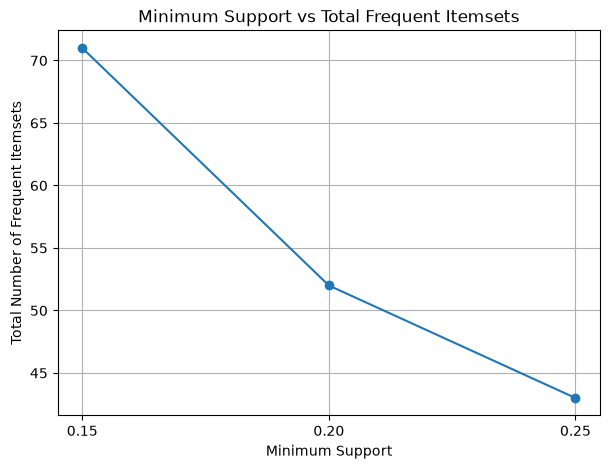

In [28]:
plt.figure(figsize=(7, 5))

plt.plot(
    support_experiment_table["Minimum Support"],
    support_experiment_table["Total Frequent Itemsets"],
    marker="o"
)

plt.xlabel("Minimum Support")
plt.ylabel("Total Number of Frequent Itemsets")
plt.title("Minimum Support vs Total Frequent Itemsets")
plt.xticks(support_thresholds)
plt.grid(True)
plt.show()


**Plot observation:** raising the minimum-support threshold makes the frequency requirement stricter and therefore cannot increase the set of frequent itemsets.

## Task 16: Effect of Minimum Confidence

Minimum support remains fixed at 0.20. Minimum confidence values are 0.50, 0.70, and 0.90.


In [29]:
confidence_thresholds = [0.50, 0.70, 0.90]
confidence_experiment_rows = []

for confidence_threshold in confidence_thresholds:
    rules = generate_rules(
        frequent_itemsets,
        transactions,
        min_confidence=confidence_threshold
    )

    confidence_experiment_rows.append({
        "Minimum Confidence": confidence_threshold,
        "Number of Strong Rules": len(rules)
    })

confidence_experiment_table = pd.DataFrame(confidence_experiment_rows)
confidence_experiment_table


,Minimum Confidence,Number of Strong Rules
0,0.5,162
1,0.7,143
2,0.9,65


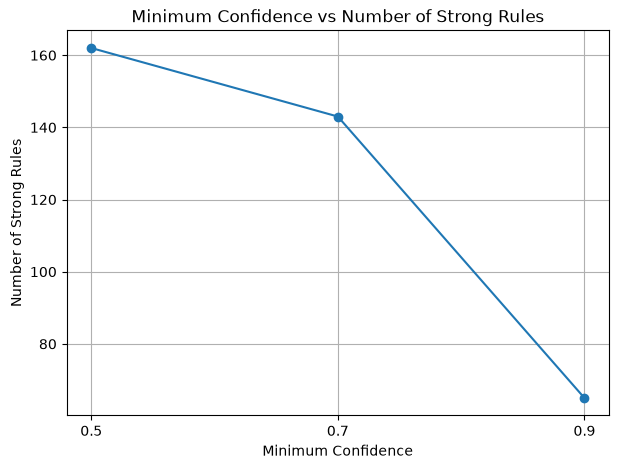

In [30]:
plt.figure(figsize=(7, 5))

plt.plot(
    confidence_experiment_table["Minimum Confidence"],
    confidence_experiment_table["Number of Strong Rules"],
    marker="o"
)

plt.xlabel("Minimum Confidence")
plt.ylabel("Number of Strong Rules")
plt.title("Minimum Confidence vs Number of Strong Rules")
plt.xticks(confidence_thresholds)
plt.grid(True)
plt.show()


**Plot observation:** Increasing minimum confidence makes the rule-acceptance condition stricter, so the set of accepted rules become smaller.


## Task 17: Compare A → B and B → A

In [31]:
# Use a pair of associated items from the frequent itemsets.
# This code selects the first available frequent 2-itemset.

frequent_pairs = frequent_itemsets.get(2, [])

if frequent_pairs:
    pair = frequent_pairs[0]
    pair_items = list(pair)

    A = {pair_items[0]}
    B = {pair_items[1]}

    comparison = pd.DataFrame([
        {
            "Rule": "A -> B",
            "Support": support(A | B, transactions),
            "Confidence": confidence(A, B, transactions)
        },
        {
            "Rule": "B -> A",
            "Support": support(B | A, transactions),
            "Confidence": confidence(B, A, transactions)
        }
    ])

    print("A =", A)
    print("B =", B)
    display(comparison)
else:
    print("No frequent 2-itemset was found.")


A = {'petal_length=high'}
B = {'petal_width=high'}


,Rule,Support,Confidence
0,A -> B,0.306667,0.901961
1,B -> A,0.306667,0.884615


**Explanation:** The support of `A ∪ B` is the same regardless of rule direction. Confidence differs because `A → B` uses `count(A)` as its denominator, whereas `B → A` uses `count(B)`.


## Task 18: Required Visualizations

### 18.1 Number of Frequent Itemsets at Each Level

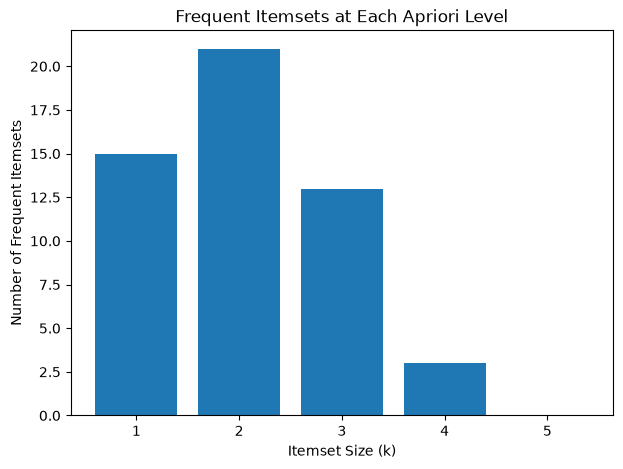

In [32]:
level_counts = pd.DataFrame([
    {"k": k, "Number of Frequent Itemsets": len(frequent_itemsets[k])}
    for k in sorted(frequent_itemsets)
])

plt.figure(figsize=(7, 5))
plt.bar(
    level_counts["k"].astype(str),
    level_counts["Number of Frequent Itemsets"]
)
plt.xlabel("Itemset Size (k)")
plt.ylabel("Number of Frequent Itemsets")
plt.title("Frequent Itemsets at Each Apriori Level")
plt.show()


### 18.2 Minimum Support vs Total Frequent Itemsets

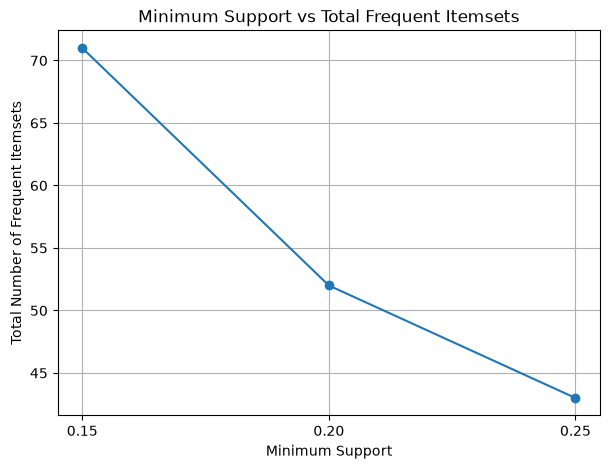

In [33]:
plt.figure(figsize=(7, 5))
plt.plot(
    support_experiment_table["Minimum Support"],
    support_experiment_table["Total Frequent Itemsets"],
    marker="o"
)
plt.xlabel("Minimum Support")
plt.ylabel("Total Number of Frequent Itemsets")
plt.title("Minimum Support vs Total Frequent Itemsets")
plt.xticks(support_thresholds)
plt.grid(True)
plt.show()


### 18.3 Minimum Confidence vs Number of Strong Rules

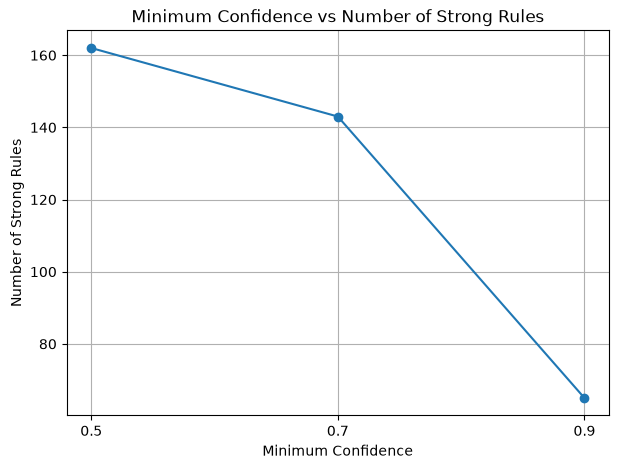

In [34]:
plt.figure(figsize=(7, 5))
plt.plot(
    confidence_experiment_table["Minimum Confidence"],
    confidence_experiment_table["Number of Strong Rules"],
    marker="o"
)
plt.xlabel("Minimum Confidence")
plt.ylabel("Number of Strong Rules")
plt.title("Minimum Confidence vs Number of Strong Rules")
plt.xticks(confidence_thresholds)
plt.grid(True)
plt.show()


### 18.4 Support vs Confidence for Final Strong Rules

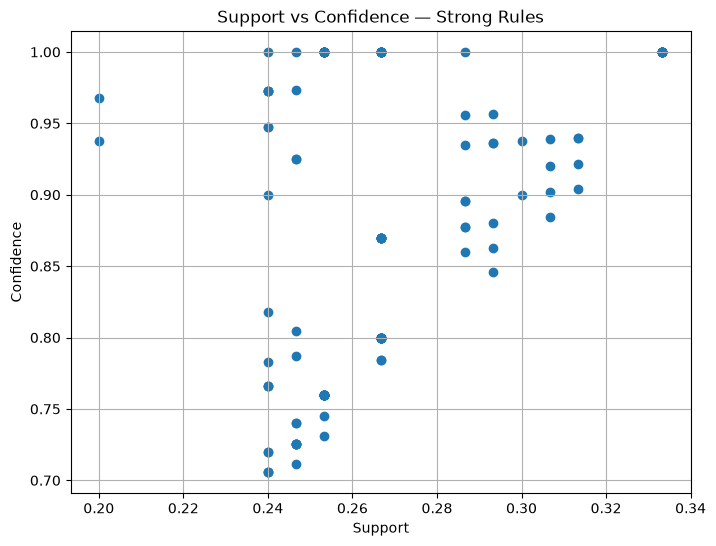

In [35]:
if not strong_rules_df.empty:
    plt.figure(figsize=(8, 6))
    plt.scatter(
        strong_rules_df["Support"],
        strong_rules_df["Confidence"]
    )
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Support vs Confidence — Strong Rules")
    plt.grid(True)
    plt.show()
else:
    print("No strong rules available to plot.")


## Task 19: Compare with the Apriori Example in the Lecture PPT

**Conceptual sequence:**

\[
C1 \rightarrow L1 \rightarrow C2 \rightarrow L2 \rightarrow C3 \rightarrow L3 \rightarrow \cdots
\]

`Ck` contains candidate `k`-itemsets, while `Lk` contains the candidates that satisfy the minimum-support requirement after pruning and support counting.

**Lecture PPT is not yet uploaded in classroom.**

**Difference from the small lecture example:** The Iris database contains many categorical items generated from four measurements plus species. It therefore represents a larger and more structured transaction database than a small hand-written transaction example.

**Why candidate generation and pruning matter more as unique items increase:** The number of possible item combinations grows rapidly as the number of unique items increases. Pruning removes candidates that cannot possibly become frequent, avoiding unnecessary support counting.

**Why Apriori requires multiple scans:** Each level needs support information for candidate itemsets of that size. The level-wise algorithm therefore repeatedly scans the transaction database to count candidate occurrences.


## Task 20: Algorithmic Complexity and Practical Observation

In [36]:
candidate_statistics["Candidates Eliminated by Pruning"] = (
    candidate_statistics["Candidates before pruning"]
    - candidate_statistics["Candidates after pruning"]
)

display(candidate_statistics)

print("At least two levels of candidate-generation statistics:")
display(candidate_statistics.head(2))


,k,Candidates before pruning,Candidates after pruning,Frequent itemsets,Candidates Eliminated by Pruning
0,1,15,15,15,0
1,2,105,105,21,0
2,3,18,15,13,3
3,4,7,3,3,4
4,5,1,0,0,1


At least two levels of candidate-generation statistics:


,k,Candidates before pruning,Candidates after pruning,Frequent itemsets,Candidates Eliminated by Pruning
0,1,15,15,15,0
1,2,105,105,21,0


**Comment:** A larger `Ck` increases processing cost because more candidates require subset checks and support counting. The Apriori property can substantially reduce this cost by eliminating candidates with infrequent subsets.

**Practical advantage:** Apriori is straightforward and interpretable because its level-wise search and support-based pruning are easy to inspect.

**Practical limitation:** Candidate generation and repeated database scans can become computationally expensive when the number of items or possible combinations becomes large.


## Task 21: Final Results Table

In [37]:
main_total_frequent = len(all_frequent_table)
main_largest_k = max(frequent_itemsets.keys())
main_strong_rules = len(strong_rules_df)

summary_rows = [
    {
        "Experiment Setting": "Main Apriori run",
        "Setting": "min support = 0.20",
        "Result to Report": f"Total frequent itemsets = {main_total_frequent}; largest k = {main_largest_k}"
    },
    {
        "Experiment Setting": "Rule generation",
        "Setting": "min confidence = 0.70",
        "Result to Report": f"Number of strong rules = {main_strong_rules}"
    }
]

for _, row in support_experiment_table.iterrows():
    level_parts = [
        f"L{k}={int(row.get(f'L{k}', 0))}"
        for k in range(1, len(frequent_itemsets) + 1)
        if f"L{k}" in row.index
    ]

    summary_rows.append({
        "Experiment Setting": "Support experiment",
        "Setting": f"min support = {row['Minimum Support']:.2f}",
        "Result to Report": ", ".join(level_parts)
    })

for _, row in confidence_experiment_table.iterrows():
    summary_rows.append({
        "Experiment Setting": "Confidence experiment",
        "Setting": f"min confidence = {row['Minimum Confidence']:.2f}",
        "Result to Report": f"Strong rules = {int(row['Number of Strong Rules'])}"
    })

final_summary = pd.DataFrame(summary_rows)
final_summary


,Experiment Setting,Setting,Result to Report
0,Main Apriori run,min support = 0.20,Total frequent itemsets = 52; largest k = 5
1,Rule generation,min confidence = 0.70,Number of strong rules = 143
2,Support experiment,min support = 0.15,"L1=15, L2=26, L3=21, L4=8, L5=1"
3,Support experiment,min support = 0.20,"L1=15, L2=21, L3=13, L4=3, L5=0"
4,Support experiment,min support = 0.25,"L1=15, L2=17, L3=9, L4=2, L5=0"
5,Confidence experiment,min confidence = 0.50,Strong rules = 162
6,Confidence experiment,min confidence = 0.70,Strong rules = 143
7,Confidence experiment,min confidence = 0.90,Strong rules = 65


## Task 22: Observations and Conclusion

### Observations about the Iris transaction database

1. The original numerical Iris attributes are converted into categorical items, allowing the records to be processed using Boolean transaction logic.
2. The Apriori algorithm searches level by level, retaining only itemsets whose support reaches the selected minimum-support threshold.
3. The Apriori property allows candidates with infrequent subsets to be removed before full support counting.
4. The final frequent itemsets describe combinations of categorical measurement levels and species labels that co-occur sufficiently often in the transaction database.
5. The exact frequent-itemset counts and largest frequent-itemset size depend on the specified quantile categorization and the chosen minimum-support threshold.
6. Association rules generated from the frequent itemsets describe recurring co-occurrence patterns in the transformed Iris records.

### Observations about support and confidence

1. Support measures how frequently an itemset occurs across the complete transaction database.
2. Confidence measures the conditional frequency of the consequent given the antecedent, so it is directional.
3. Increasing minimum support or minimum confidence makes the corresponding acceptance criterion stricter.

### Effect of the Apriori property

The Apriori property reduces the candidate search space because a candidate cannot be frequent if any of its required subsets is already known to be infrequent.

### Effect of the thresholds

Increasing minimum support generally reduces the number of frequent itemsets because fewer itemsets satisfy the frequency requirement. Increasing minimum confidence generally reduces the number of accepted association rules because fewer rules satisfy the stronger conditional-frequency requirement.

### Conclusion

Apriori provides a level-wise method for discovering frequent combinations and deriving association rules from transaction data. The same general approach can be applied to applications such as market-basket analysis, shelf management, inventory control, and document analysis, provided the underlying data can be represented as transactions containing categorical items.
